In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160)
OUT = ROOT / "outputs"
def show(name): display(Image(filename=str(OUT / "figures" / f"{name}.png")))


# 06 Portfolio construction
Weight rules evaluated on one date using only past data.

In [2]:
from src.data.align import load_processed
from src.portfolio import benchmarks as B
from src.portfolio.constraints import check_weights
ind, aux = load_processed()
i = ind.index.get_loc(pd.Timestamp("2008-08-29"))
hist = ind.iloc[: i + 1]
w = pd.DataFrame({
    "EqualWeight": B.equal_weight(hist),
    "MinVariance": B.minimum_variance(hist, cov_window=756, max_weight=0.35),
    "MeanVariance": B.mean_variance(hist, cov_window=756, max_weight=0.35, risk_aversion=5, shrinkage=0.9),
}, index=ind.columns)
for c in w: check_weights(w[c].values, 0.35)
w.round(3)

,EqualWeight,MinVariance,MeanVariance
asset_id,,,
NoDur,0.1,0.350,0.350
Durbl,0.1,0.000,0.000
Manuf,0.1,0.000,0.029
Enrgy,0.1,0.000,0.014
HiTec,0.1,0.000,0.000
Telcm,0.1,0.072,0.010
Shops,0.1,0.000,0.000
Hlth,0.1,0.350,0.350
Utils,0.1,0.228,0.247


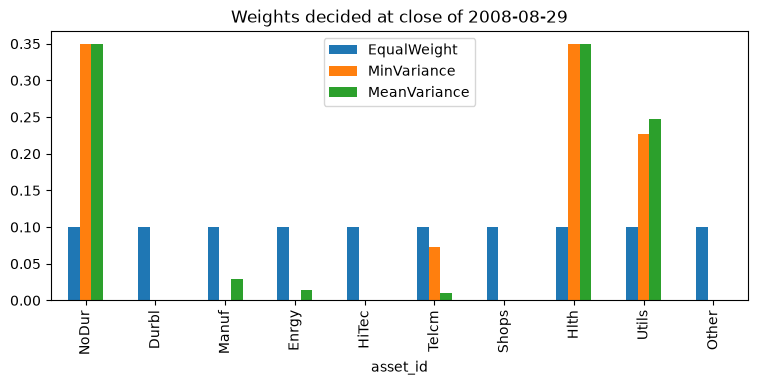

volatility-adaptive exposure for forecast vols 10%/20%/40% (target 10%): [1.0, 0.5, 0.25]


In [3]:
w.plot.bar(figsize=(9, 3.5), title="Weights decided at close of 2008-08-29"); plt.show()
print("volatility-adaptive exposure for forecast vols 10%/20%/40% (target 10%):",
      [round(float(B.vol_adaptive(hist, v, 0.10).sum()), 3) for v in (0.10, 0.20, 0.40)])

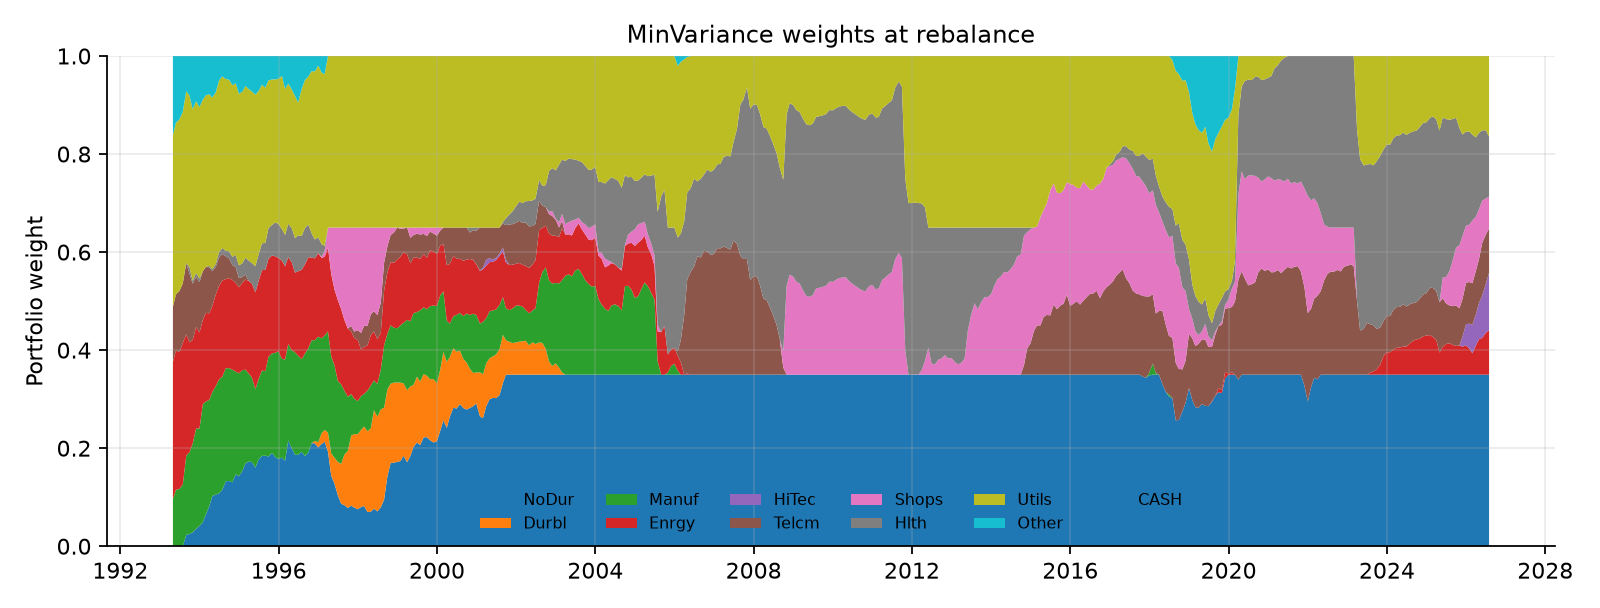

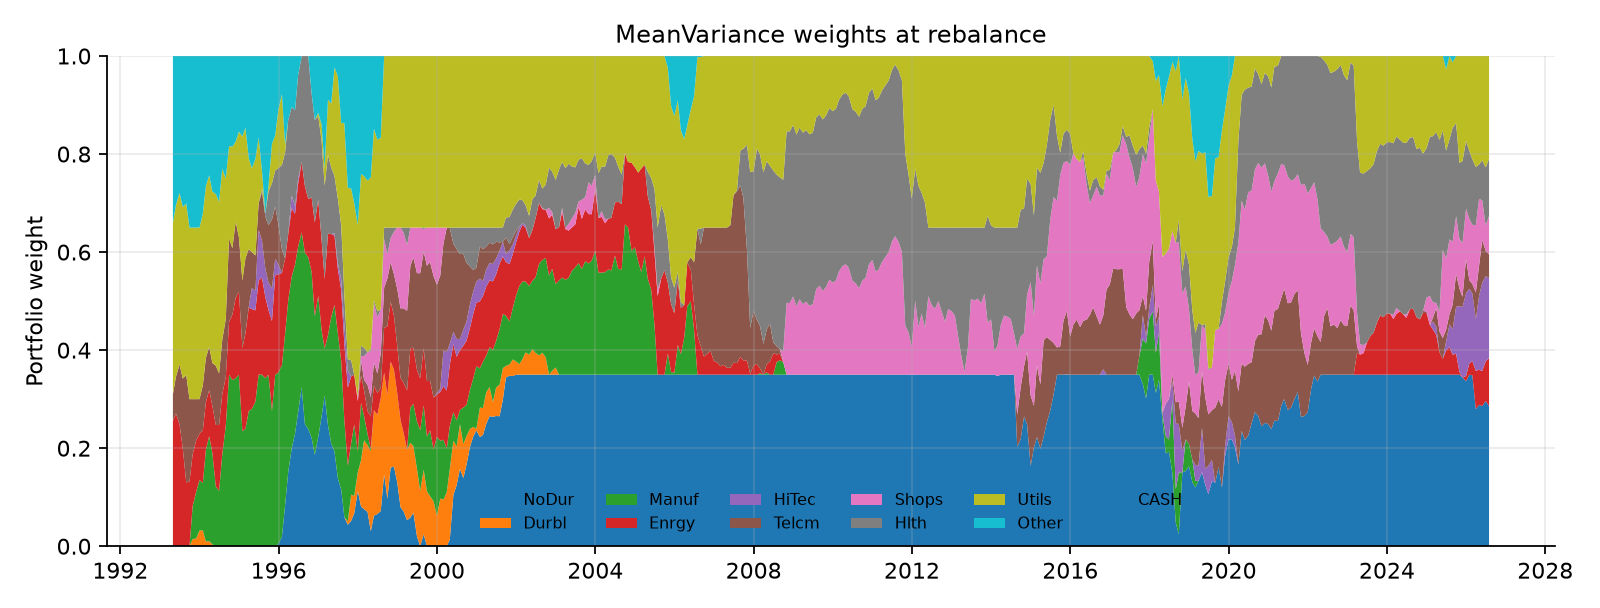

In [4]:
show('fig_weights_MinVariance'); show('fig_weights_MeanVariance')